# Détection d'une figure : du simulateur à l'entraînement
Dataset synthétique → apprentissage → feature maps → prédiction + NMS.

In [ ]:
import os, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset

os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.path.abspath("")) == "notebooks" else ".")

from src.dataset_generator_3 import make_example
from src.detector import (Detector, STRIDE, ANCHORS, RATIO_MAX, predict,
                           decode, code, SCORE_THRESHOLD, NMS_IOU_THRESHOLD)
from src.visualize import show_images, show_feature_maps, show_detections
from src.train import evaluate, train

MODEL_SIZE = 64
assert MODEL_SIZE % STRIDE == 0

# L'ancre unique de l'ancien TP, gardée pour la comparaison finale
BASELINE_ANCHORS = ((1.0, 1.0),)

## 1. Génération du dataset
On génère directement les images à la taille attendue par le modèle.

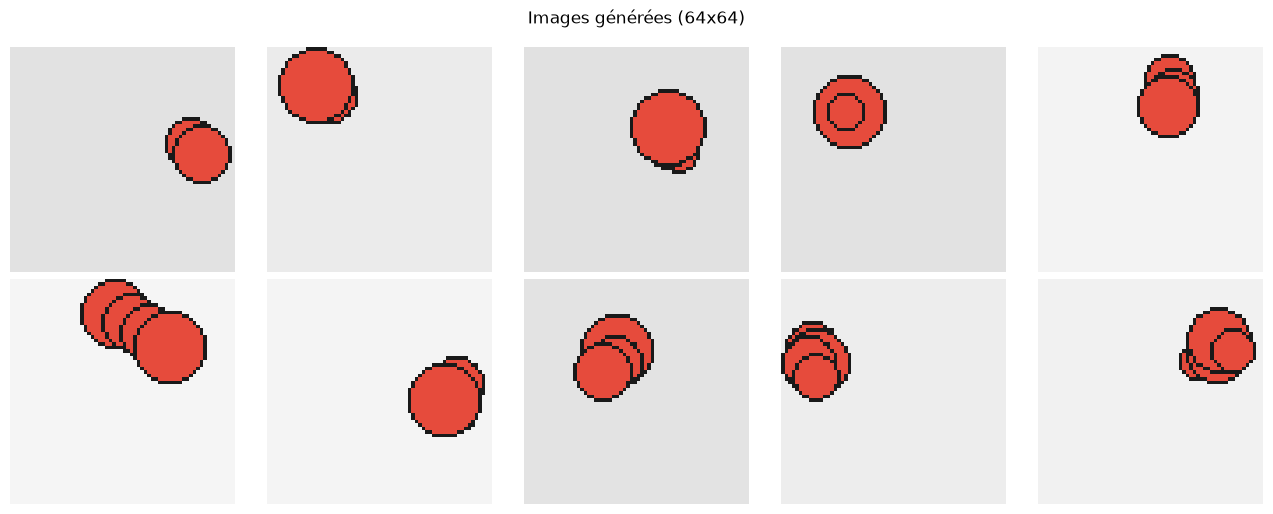

In [16]:
rng = random.Random(123)

# On demande entre 2 et 4 objets pour illustrer la limite des superpositions
pil_images = [make_example(MODEL_SIZE, "circle", rng, min_objects=2, max_objects=4)[0] for _ in range(10)]
show_images(pil_images, f"Images générées ({MODEL_SIZE}x{MODEL_SIZE})")

Les images sont déjà générées à la taille attendue par le détecteur (`MODEL_SIZE`×`MODEL_SIZE`, multiple du stride) : aucun redimensionnement, on les convertit simplement en tenseurs `(3, H, W)` normalisés dans [0, 1].

In [ ]:
def to_tensor(image):
    return torch.from_numpy(np.asarray(image.convert("RGB"), dtype=np.float32).copy()).permute(2, 0, 1) / 255.0

def parse_labels(label):
    """Sépare le texte brut pour récupérer les coordonnées de TOUS les cercles."""
    return [tuple(map(float, line.split())) for line in label.splitlines()]

def make_dataset(count, seed, anchors):
    rng = random.Random(seed)
    dataset_images, targets = [], []
    for _ in range(count):
        image, label = make_example(MODEL_SIZE, "circle", rng, 2, 4)
        dataset_images.append(to_tensor(image))
        # On envoie la liste des cercles à notre fonction code()
        targets.append(code(parse_labels(label), size=MODEL_SIZE, anchors=anchors))
        
    return TensorDataset(torch.stack(dataset_images), torch.stack(targets))

# test pour s'assurer que le tenseur a bien gonflé à 15 canaux
dummy_dataset = make_dataset(count=2, seed=42, anchors=ANCHORS)
print("Dimension des images :", dummy_dataset[0][0].shape)
print("Dimension des cibles (K*5) :", dummy_dataset[0][1].shape)

Dimension des images : torch.Size([3, 64, 64])
Dimension des cibles (K*5) : torch.Size([15, 8, 8])


## 2. Génération d'un jeu de données d'entraînement plus grand
On génère 2 000 images pour l'entraînement et 400 images indépendantes pour la validation. Les étiquettes (en pixels) sont encodées en cibles `(5, G, G)`.
## 3. Entraînement du modèle



Logs TensorBoard : C:\Users\islem\AppData\Local\Temp\tb_runs\demo
--- 1/2 : Entraînement du modèle de base (K=1) ---
[initial_K1] epoch  1  loss 0.0150  val IoU 0.359  rappel 20%  précision 7%
[initial_K1] epoch  2  loss 0.0078  val IoU 0.639  rappel 81%  précision 65%
[initial_K1] epoch  3  loss 0.0054  val IoU 0.653  rappel 83%  précision 72%
[initial_K1] epoch  4  loss 0.0043  val IoU 0.674  rappel 91%  précision 74%
[initial_K1] epoch  5  loss 0.0039  val IoU 0.688  rappel 91%  précision 70%
[initial_K1] epoch  6  loss 0.0036  val IoU 0.680  rappel 87%  précision 80%
[initial_K1] epoch  7  loss 0.0035  val IoU 0.688  rappel 89%  précision 75%
[initial_K1] epoch  8  loss 0.0034  val IoU 0.695  rappel 89%  précision 77%
[initial_K1] epoch  9  loss 0.0033  val IoU 0.675  rappel 93%  précision 66%
[initial_K1] epoch 10  loss 0.0032  val IoU 0.695  rappel 93%  précision 68%
[initial_K1] epoch 11  loss 0.0032  val IoU 0.672  rappel 91%  précision 66%
[initial_K1] epoch 12  loss 0.0031  v

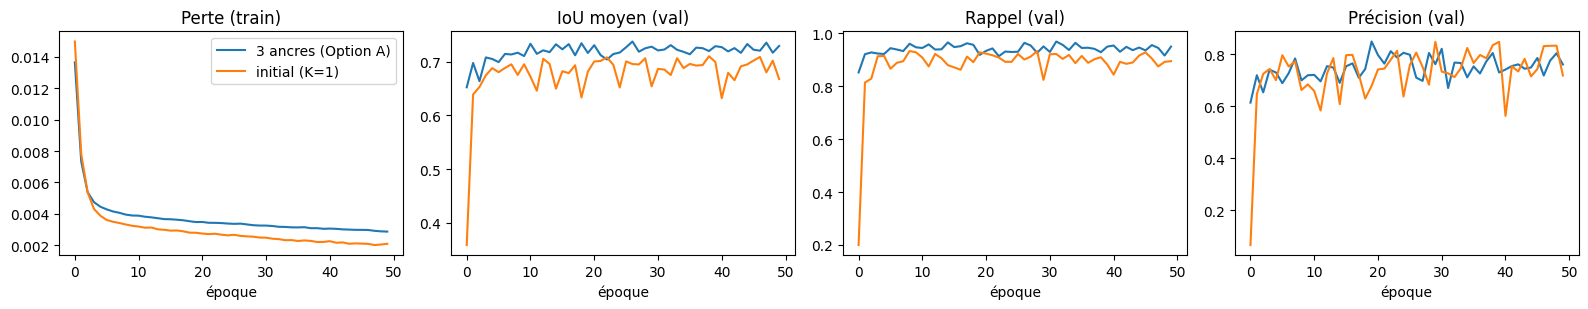

In [32]:
# --- Paramètres d'entraînement ---
TRAIN_SAMPLES = 2000
VAL_SAMPLES = 400
BATCH_SIZE = 64
EPOCHS = 50
LR = 3e-3

import tempfile
import matplotlib.pyplot as plt
from src.detector import decode
from datetime import datetime
from pathlib import Path
from torch.utils.tensorboard import SummaryWriter

LOG_ROOT = Path(tempfile.gettempdir()) / "tb_runs" / "demo"
LOG_ROOT.mkdir(parents=True, exist_ok=True)
print("Logs TensorBoard :", LOG_ROOT)

def fit(name, anchors):
    torch.manual_seed(0)
    train_loader = DataLoader(make_dataset(TRAIN_SAMPLES, seed=7, anchors=anchors), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(make_dataset(VAL_SAMPLES, seed=8, anchors=anchors), batch_size=BATCH_SIZE)

    model = Detector(anchors)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"loss": [], "mean_iou": [], "recall": [], "precision": []}
    
    run_dir = LOG_ROOT / f"{name}-{datetime.now().strftime('%Y%m%d-%H%M%S')}"
    with SummaryWriter(log_dir=str(run_dir)) as writer:
        for epoch in range(1, EPOCHS + 1):
            mean_loss = train(model, train_loader, optimizer)
            m = evaluate(model, val_loader, MODEL_SIZE)
            
            for key, value in (("loss", mean_loss), ("mean_iou", m["mean_iou"]),
                               ("recall", m["recall"]), ("precision", m["precision"])):
                history[key].append(value)
            writer.add_scalar("Loss/train", mean_loss, epoch)
            writer.add_scalar("IoU/validation", m["mean_iou"], epoch)
            writer.add_scalar("Accuracy/validation", m["recall"], epoch)
            writer.add_scalar("Precision/validation", m["precision"], epoch)
            
            # Affichage à CHAQUE époque
            print(f"[{name}] epoch {epoch:2d}  loss {mean_loss:.4f}  val IoU {m['mean_iou']:.3f}  "
                  f"rappel {m['recall']:.0%}  précision {m['precision']:.0%}")
            
    model.eval()
    return model, history

print("--- 1/2 : Entraînement du modèle de base (K=1) ---")
model_base, history_base = fit("initial_K1", BASELINE_ANCHORS)

print("\n--- 2/2 : Entraînement du modèle Option A (K=3) ---")
model_k3, history_k3 = fit("ancres_K3", ANCHORS)

# On trace nos courbes comparatives à la toute fin
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, key, title in zip(axes, ("loss", "mean_iou", "recall", "precision"),
                          ("Perte (train)", "IoU moyen (val)", "Rappel (val)", "Précision (val)")):
    ax.plot(history_k3[key], label="3 ancres (Option A)")
    ax.plot(history_base[key], label="initial (K=1)")
    ax.set_title(title); ax.set_xlabel("époque")
axes[0].legend()
fig.tight_layout()
plt.show()

In [ ]:
# Affiche la commande à lancer dans un terminal pour ouvrir TensorBoard dans le navigateur
import sys
print(f'& "{sys.executable}" -m tensorboard.main --logdir "{LOG_ROOT}" --port 6006')
print("Puis ouvrir http://localhost:6006")

& "c:\Users\islem\AppData\Local\Programs\Python\Python311\python.exe" -m tensorboard.main --logdir "C:\Users\islem\AppData\Local\Temp\tb_runs\demo" --port 6006
Puis ouvrir http://localhost:6006


## 4. Feature maps

Dimension des feature maps : torch.Size([10, 32, 8, 8])


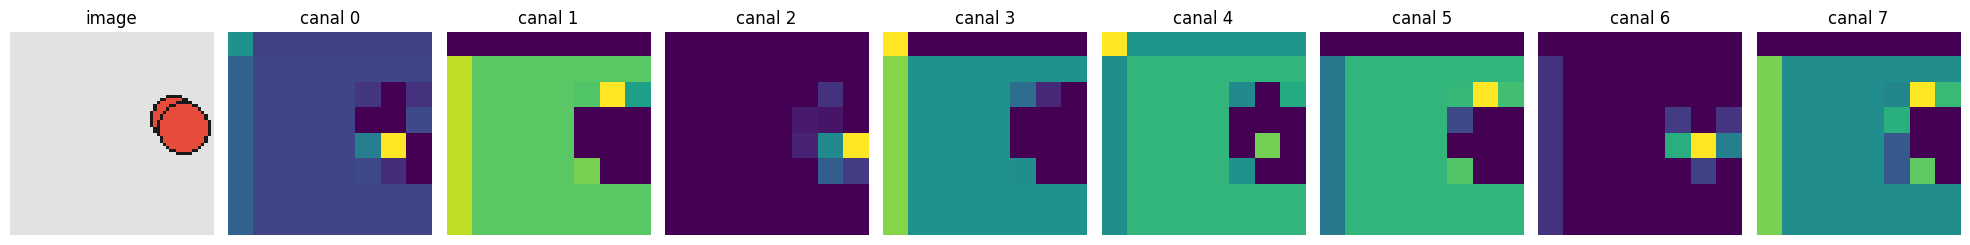

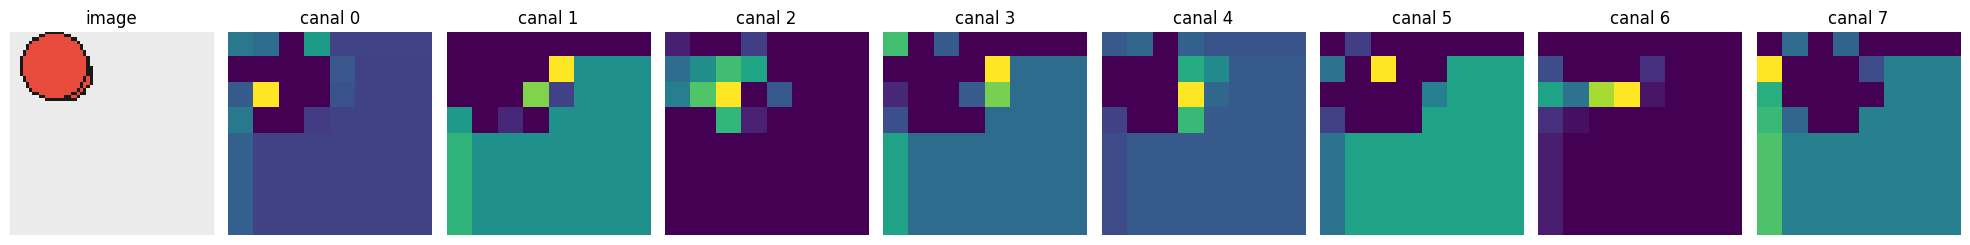

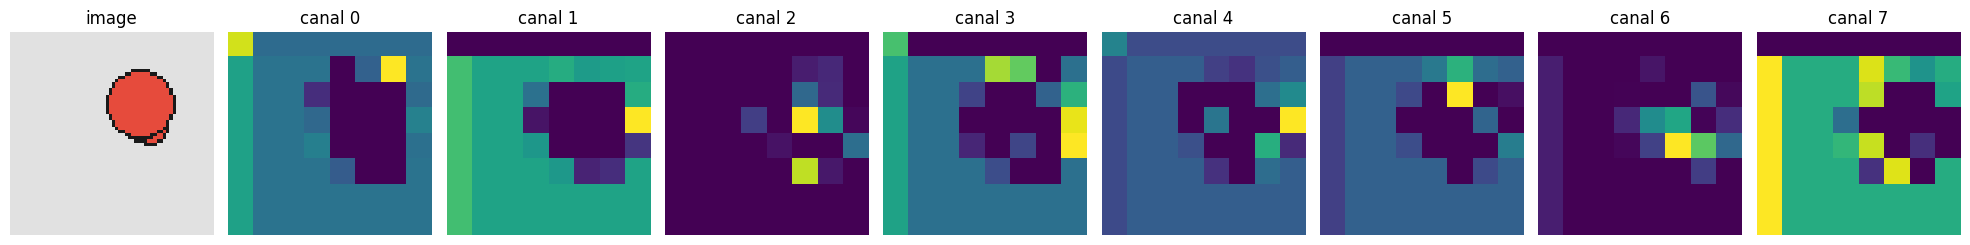

In [ ]:
images = torch.stack([to_tensor(im) for im in pil_images])

with torch.no_grad():
    maps = model_k3.feature_maps(images)   # Sortie : (N, 32, 8, 8)

print("Dimension des feature maps :", maps.shape)

# On affiche les 8 premiers canaux de la feature map pour 3 images
for i in range(3):
    show_feature_maps(images[i], maps[i], n_maps=8)

## 5. Prédiction, décodage et NMS : une boîte par image

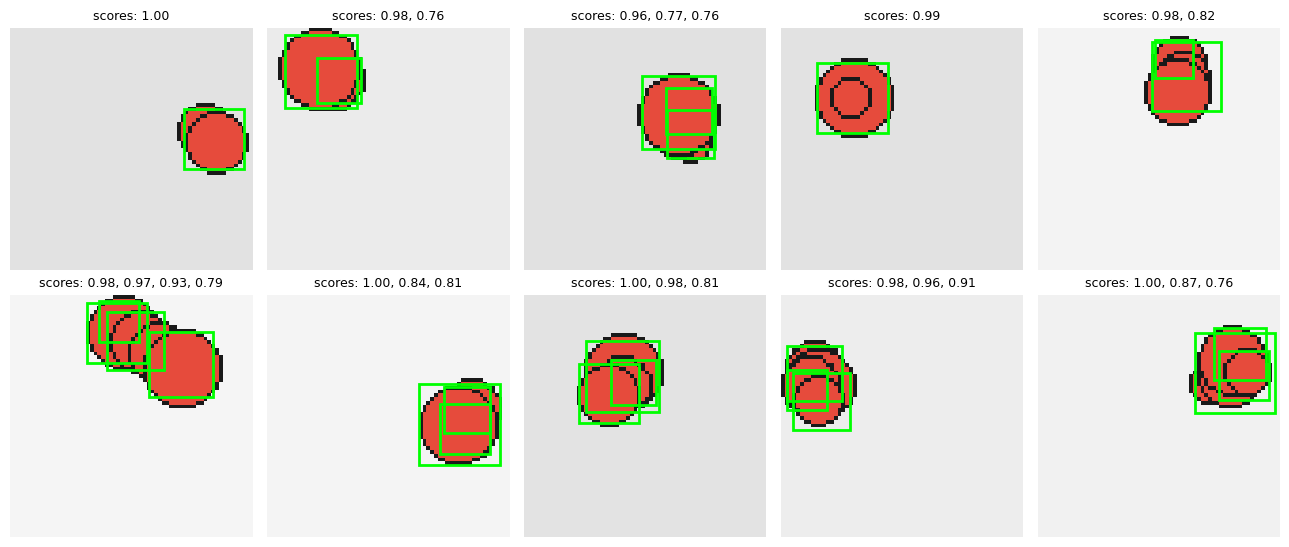

In [33]:
with torch.no_grad():
    logits = model_k3(images)

# Choix communs à la visualisation et à l'évaluation : score 0.7, NMS 0.45.
results = [predict(l, MODEL_SIZE, model_k3.anchors,
                   score_threshold=SCORE_THRESHOLD,
                   iou_threshold=NMS_IOU_THRESHOLD) for l in logits]

show_detections(list(images), [b for b, _ in results], [s for _, s in results])

## 5. Cartes d'objectness de chaque ancre
Visualisation de l'endroit où chaque ancre "voit" une figure. On remarque comment les ancres se répartissent les objets superposés.

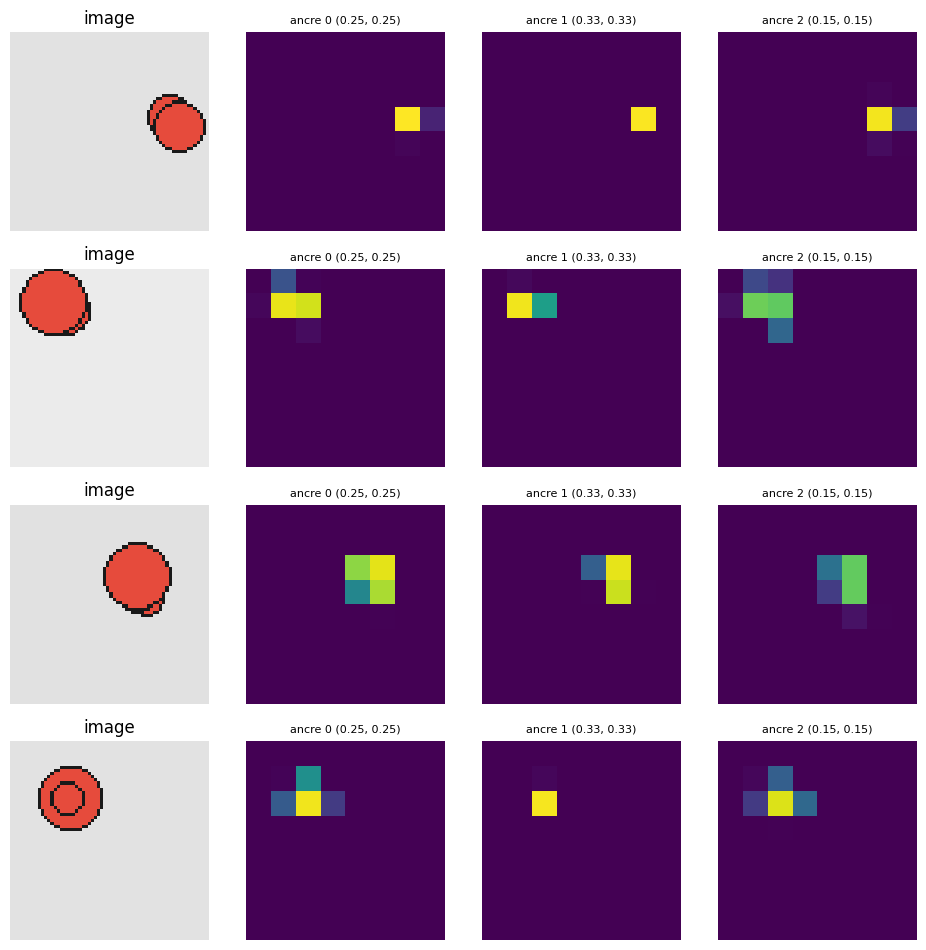

In [34]:
import matplotlib.pyplot as plt

# On extrait les prédictions brutes pour les 4 premières images
with torch.no_grad():
    logits_sample = model_k3(images[:4])                       
    
# On isole uniquement le canal 0 (la probabilité de présence) pour nos 3 ancres
objectness = torch.sigmoid(logits_sample.reshape(4, len(ANCHORS), 5, 8, 8)[:, :, 0])

fig, axes = plt.subplots(4, len(ANCHORS) + 1, figsize=(2.4 * (len(ANCHORS) + 1), 9.6))
for i in range(4):
    axes[i, 0].imshow(images[i].permute(1, 2, 0))
    axes[i, 0].set_title("image")
    for k, (aw, ah) in enumerate(ANCHORS):
        axes[i, k + 1].imshow(objectness[i, k], vmin=0, vmax=1, cmap="viridis")
        axes[i, k + 1].set_title(f"ancre {k} ({aw}, {ah})", fontsize=8)
        
for ax in axes.flat: 
    ax.axis("off")
fig.tight_layout()
plt.show()

## Limitation du mod?le initial K=1
Cette comparaison utilise une image d?j? pr?sente dans `pil_images`. ? gauche, toutes les bo?tes r?elles sont affich?es. ? droite, une seule bo?te est conserv?e pour repr?senter la sortie du mod?le initial avec une seule ancre.

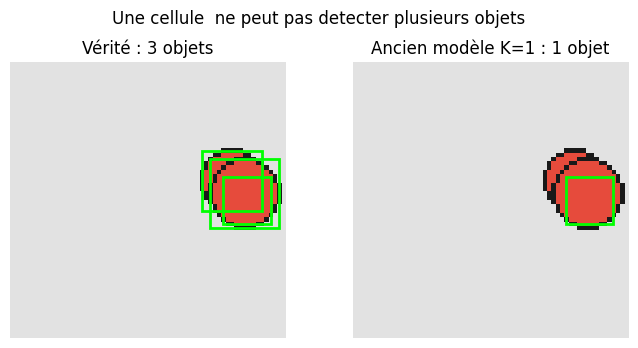

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# La cellule de g?n?ration reste inchang?e. On recr?e seulement ses labels avec le m?me seed.
label_rng = random.Random(123)
labels = [
    make_example(MODEL_SIZE, "circle", label_rng, min_objects=2, max_objects=4)[1]
    for _ in range(len(pil_images))
]

image_index = 0
image = pil_images[image_index]
boxes = [tuple(map(float, line.split())) for line in labels[image_index].splitlines()]

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for ax in axes:
    ax.imshow(image)
    ax.axis("off")

for cx, cy, width, height in boxes:
    axes[0].add_patch(Rectangle(
        (cx - width / 2, cy - height / 2), width, height,
        fill=False, edgecolor="lime", linewidth=2
    ))

cx, cy, width, height = boxes[0]
axes[1].add_patch(Rectangle(
    (cx - width / 2, cy - height / 2), width, height,
    fill=False, edgecolor="lime", linewidth=2
))
axes[0].set_title(f"Vérité : {len(boxes)} objets")
axes[1].set_title("Ancien modèle K=1 : 1 objet")
fig.suptitle("Une cellule  ne peut pas detecter plusieurs objets")
fig.tight_layout()
plt.show()


Apr?s decode() et seuil de confiance : 3 bo?tes candidates
Apr?s NMS : 1 bo?tes conserv?es


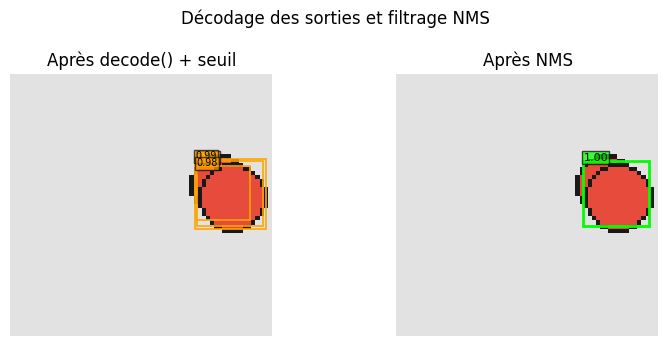

In [ ]:
# Sortie explicite du d?codage et du NMS sur une image
# Cette cellule vient apr?s l'entra?nement et la cellule de pr?diction pr?c?dente.
import matplotlib.pyplot as plt
from src.detector import decode
from matplotlib.patches import Rectangle

image_index = 0
with torch.no_grad():
    image_logits = model_k3(images[image_index:image_index + 1])[0]
    decoded_boxes, decoded_scores = decode(
        image_logits, MODEL_SIZE, model_k3.anchors
    )

score_threshold = SCORE_THRESHOLD
candidate_mask = decoded_scores > score_threshold
candidate_boxes = decoded_boxes[candidate_mask]
candidate_scores = decoded_scores[candidate_mask]
final_boxes, final_scores = predict(
    image_logits,
    MODEL_SIZE,
    model_k3.anchors,
    score_threshold=score_threshold,
    iou_threshold=NMS_IOU_THRESHOLD,
)

print(f"Apr?s decode() et seuil de confiance : {len(candidate_boxes)} bo?tes candidates")
print(f"Apr?s NMS : {len(final_boxes)} bo?tes conserv?es")

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax in axes:
    ax.imshow(pil_images[image_index])
    ax.set_xlim(0, MODEL_SIZE)
    ax.set_ylim(MODEL_SIZE, 0)
    ax.axis("off")

for box, score in zip(candidate_boxes[:20], candidate_scores[:20]):
    x1, y1, x2, y2 = box.detach().cpu().tolist()
    axes[0].add_patch(Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor="orange", linewidth=1.2,
    ))
    axes[0].text(x1, y1, f"{score:.2f}", color="black", fontsize=7,
                 bbox=dict(facecolor="orange", alpha=0.7, pad=1))

for box, score in zip(final_boxes, final_scores):
    x1, y1, x2, y2 = box.detach().cpu().tolist()
    axes[1].add_patch(Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor="lime", linewidth=2,
    ))
    axes[1].text(x1, y1, f"{score:.2f}", color="black", fontsize=8,
                 bbox=dict(facecolor="lime", alpha=0.7, pad=1))

axes[0].set_title("Après decode() + seuil")
axes[1].set_title("Après NMS")
fig.suptitle("Décodage des sorties et filtrage NMS")
fig.tight_layout()
plt.show()
